# 6.1 Understanding the Transformer Architecture

**Module 6 · Note 1**

Module 5 ended with a cliffhanger. In Note 5.4 we saw that recurrent networks pass information along a chain, one step at a time, squeezing everything through a fixed-size memory. Then we built a single attention step, in which every position could look *directly* at every other position, and saw that its learning signal did not fade with distance.

The **Transformer** is what you get when you build an entire network around that idea. It was introduced in a research paper titled *"Attention Is All You Need"*, originally for machine translation, and it has since become the architecture behind almost every major language model, including the large chat assistants you may have used, as well as many modern image, audio and multimodal models.

This module follows the whole-to-parts approach. In this first note, we look at the Transformer as **one complete system**: what goes in, what comes out, what each major part is for, and how the different families of Transformer differ. We will build a small working Transformer straight away from PyTorch's ready-made parts, so that you can see the whole machine run before we take it apart. In Notes 6.2 to 6.5 we examine each part in detail and rebuild it ourselves, and in Note 6.6 we train it to write text.

**Key question:** *What is a Transformer, as a whole, and how does information flow through it?*

**By the end of this note you will be able to:**
- describe the Transformer as a pipeline from tokens to predictions, naming each stage;
- explain what problem the Transformer was designed to solve;
- explain the roles of token embeddings, positional information, attention, feed-forward networks and the output head;
- distinguish encoder-only, decoder-only and encoder–decoder Transformers, and the masks they use;
- trace the shape of the data through a Transformer, layer by layer.

**Before you start:** complete Module 5, especially Notes 5.3 (embeddings) and 5.4 (from sequences to attention).

### Setup

Run this cell first. This note trains nothing; it only builds models and passes data through them, so it runs in seconds.

In [1]:
import os, gzip, math, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)
print("PyTorch", torch.__version__)

PyTorch 2.14.1+cu130


## 1. The Big Picture: What Is a Transformer?

A Transformer is a network that takes a **sequence of tokens** and produces a **new vector for every token**, where each new vector has been enriched with information from the other tokens in the sequence. Stack enough of these enrichment steps, add a final layer that turns vectors into predictions, and you have a model that can classify text, translate it, or generate it one token at a time.

It helps to think of a Transformer as a meeting. Each token arrives with its own notes (its embedding). In each round of the meeting, every token gets to listen to the others, decide who is relevant to it, and update its notes accordingly. That listening is **attention**. Between rounds, each token also takes a moment to think privately about what it has heard: that is the **feed-forward network**. After several rounds, each token's notes describe not just itself, but its role in the whole sequence.

Throughout this module, we work with **Tiny Shakespeare**: about a million characters of Shakespeare's plays in one text file. Our models will read and write it one character at a time, which keeps the vocabulary tiny and lets us train on a CPU.

In [2]:
os.makedirs("data/shakespeare", exist_ok=True)
PATH = "data/shakespeare/input.txt"
if not os.path.exists(PATH):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", PATH)
text = open(PATH, encoding="utf-8").read()
chars = sorted(set(text))
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(itos[i] for i in ids)
print("characters in the file:", len(text), "| distinct characters (vocabulary):", len(chars))
print(text[:100])
print(encode("First Citizen"))

characters in the file: 1115394 | distinct characters (vocabulary): 65
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You
[18, 47, 56, 57, 58, 1, 15, 47, 58, 47, 64, 43, 52]


The file contains 1,115,394 characters, built from just 65 distinct characters: letters, digits, punctuation, the space and the newline. Each character gets a number, its **token ID**; "First Citizen" becomes `[18, 47, 56, 57, 58, 1, 15, 47, 58, 47, 64, 43, 52]`. (We look at tokenisation properly in Note 6.2.)

Now here is a complete, working Transformer. We build it from PyTorch's ready-made `nn.TransformerEncoderLayer`, so it fits in a few lines. Don't worry about every argument yet: by the end of the module you will have rebuilt each piece yourself. For now, read it as a list of stages:

1. `tok_emb` turns each token ID into a vector of 64 numbers.
2. `pos_emb` adds a vector that encodes each token's **position** in the sequence.
3. `blocks` is a stack of 3 **Transformer blocks**, each containing attention and a feed-forward network.
4. `ln_f` is a final normalisation step.
5. `head` turns each token's final vector into a **score for every token in the vocabulary**: a prediction of what comes next.

In [3]:
VOCAB, D_MODEL, N_HEADS, N_LAYERS, CONTEXT = len(chars), 64, 4, 3, 64

class TinyTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.tok_emb = nn.Embedding(VOCAB, D_MODEL)          # token id  -> vector
        self.pos_emb = nn.Embedding(CONTEXT, D_MODEL)        # position  -> vector
        layer = nn.TransformerEncoderLayer(D_MODEL, N_HEADS, dim_feedforward=4 * D_MODEL,
                                           dropout=0.0, activation="gelu",
                                           batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(layer, N_LAYERS, enable_nested_tensor=False)
        self.ln_f = nn.LayerNorm(D_MODEL)
        self.head = nn.Linear(D_MODEL, VOCAB)                # vector    -> score for every token
    def forward(self, ids, causal=True):
        T = ids.shape[1]
        x = self.tok_emb(ids) + self.pos_emb(torch.arange(T))
        mask = nn.Transformer.generate_square_subsequent_mask(T) if causal else None
        x = self.blocks(x, mask=mask, is_causal=causal)
        return self.head(self.ln_f(x))

torch.manual_seed(0)
model = TinyTransformer()
print("parameters:", sum(p.numel() for p in model.parameters()))

parameters: 162561


Our tiny Transformer has 162,561 parameters. That is minuscule by modern standards, but it has all the essential parts of the models behind today's chat assistants.

> 🖼 *IMAGE 6.1.1 — The Transformer at a Glance.* A vertical stack diagram on a white background, read bottom to top. At the bottom, a row of six character tiles "F", "i", "r", "s", "t", " " labelled "input tokens". Above each tile, a small grey vector bar labelled "token embedding", plus a small striped bar beside it labelled "+ position embedding". Above that, a large rounded rectangle labelled "Transformer block × 3", drawn as a slightly 3D stack of three identical cards. Inside the front card, two stacked sub-boxes: a blue box "attention: tokens exchange information" with criss-crossing thin lines between six small circles, and an orange box "feed-forward: each token thinks on its own" with six separate small arrows. Above the stack, a thin grey box "final layer norm", then a green box "output head", then at the top six small bar charts (one above each position), each with one tallest bar, labelled "next-token predictions (65 scores each)". Takeaway: a Transformer turns a sequence of tokens into a sequence of predictions through embeddings, a stack of blocks and an output head.

## 2. What Problem Were Transformers Designed to Address?

In Note 5.4 we found three problems with recurrent networks:

- **A long chain:** information, and the learning signal, has to pass through every step between two distant tokens, and fades along the way.
- **A fixed-size bottleneck:** everything read so far must be squeezed into one hidden state.
- **Sequential computation:** step 1,000 cannot start until step 999 has finished, so the parallel power of modern hardware is wasted.

The Transformer removes all three. Every token can attend directly to every other token, so the chain has length one. Every token keeps its own vector, so there is no single bottleneck. And because no token has to wait for the previous one, the whole sequence is processed **at once**. Let's see that last point concretely.

In [4]:
ids = torch.tensor([encode("First Citizen:\nBefore we proceed")])     # 32 characters
with torch.no_grad():
    out = model(ids)
print("predictions made in ONE forward pass:", out.shape[0] * out.shape[1], "(one per position)")
print("an RNN would need", ids.shape[1], "sequential steps to read the same input")

predictions made in ONE forward pass: 32 (one per position)
an RNN would need 32 sequential steps to read the same input


For our 32-character input, a single forward pass of the Transformer produces 32 predictions at once: one at every position, each saying what character should come next *at that point*. An RNN reading the same input would need 32 steps, one after another.

This matters most during training. With one forward pass, we get a prediction, and therefore a training signal, at every position of every sequence in the batch. That is a key reason Transformers can be trained on enormous amounts of text. We return to this idea, called **parallel training**, in Note 6.6.

The price, as you saw at the end of Note 5.4, is that comparing every token with every other token costs work proportional to the *square* of the sequence length. We measure that cost in Note 6.3.

## 3. The Transformer as a Complete Information-Processing System

Let's follow one input all the way through our model, and print the shape of the data after each stage. We use the first 32 characters of the play as input.

In [5]:
ids = torch.tensor([encode("First Citizen:\nBefore we proceed")])     # (1, T)
print("input ids:", tuple(ids.shape))
x = model.tok_emb(ids) + model.pos_emb(torch.arange(ids.shape[1]))
print("after token + position embeddings:", tuple(x.shape))
for i, block in enumerate(model.blocks.layers):
    x = block(x, src_mask=nn.Transformer.generate_square_subsequent_mask(ids.shape[1]), is_causal=True)
    print(f"after block {i + 1}:", tuple(x.shape))
logits = model.head(model.ln_f(x))
print("logits (one score per vocabulary entry, at every position):", tuple(logits.shape))

input ids: (1, 32)
after token + position embeddings: (1, 32, 64)
after block 1: (1, 32, 64)
after block 2: (1, 32, 64)
after block 3: (1, 32, 64)
logits (one score per vocabulary entry, at every position): (1, 32, 65)


Read the shapes from top to bottom:

- The input is `(1, 32)`: a batch of 1 sequence, 32 token IDs long.
- After the embeddings it is `(1, 32, 64)`: each of the 32 tokens is now a vector of 64 numbers. This size, called **`d_model`** or the **model dimension**, is the "width" of the Transformer.
- After each of the 3 blocks it is **still** `(1, 32, 64)`. Blocks never change the shape; they change the *content* of each token's vector, by mixing in information from other tokens.
- After the output head it is `(1, 32, 65)`: at every one of the 32 positions, one score for each of the 65 characters in the vocabulary. These scores are called **logits**.

That constant shape inside the stack is one of the Transformer's most useful properties. Because each block takes `(batch, tokens, d_model)` and returns the same shape, you can stack as many blocks as you like, and the same block design works for any length of input up to the maximum context.

What does the untrained model predict? Let's turn the logits at the last position into probabilities with softmax and look at its best guesses for the character after "proceed".

In [6]:
with torch.no_grad():
    probs = model(ids).softmax(-1)[0, -1]          # distribution for the character after "proceed"
top = probs.topk(5)
print("untrained model's top-5 guesses for the next character:",
      [(repr(itos[i.item()]), round(p.item(), 3)) for p, i in zip(top.values, top.indices)])
entropy = -(probs * probs.log()).sum().item()
print(f"entropy of that distribution: {entropy:.3f} | maximum possible, ln({VOCAB}): {math.log(VOCAB):.3f}")

untrained model's top-5 guesses for the next character: [("'i'", 0.065), ("'N'", 0.041), ("'R'", 0.035), ("' '", 0.03), ("'-'", 0.029)]
entropy of that distribution: 4.024 | maximum possible, ln(65): 4.174


The untrained model's favourite guess is `'i'` with probability 0.065, followed by `'N'`, `'R'`, a space and `'-'`. These are random preferences, not knowledge. The **entropy** of the distribution, a measure of how spread out it is, is 4.024. The maximum possible, for a perfectly uniform guess among 65 characters, is ln(65) = 4.174. So the untrained model is close to "no idea at all", which is exactly where training will start from in Note 6.6.

> **Key terms**
> - **Transformer:** a network built from stacked blocks of attention and feed-forward layers that processes all tokens of a sequence in parallel.
> - **Model dimension (`d_model`):** the length of each token's vector inside the Transformer.
> - **Transformer block:** one round of attention plus feed-forward processing; input and output have the same shape.
> - **Logits:** the raw scores the output head produces, one per vocabulary entry; softmax turns them into probabilities.
> - **Entropy:** a measure of how uncertain a probability distribution is; highest when every outcome is equally likely.

> **Check yourself 1.** If we fed our model a batch of 8 sequences, each 50 characters long, what would be the shape of the logits?

## 4. The Roles of Tokens, Embeddings, Attention, and Feed-Forward Networks

Each stage of the pipeline has one job. Here they are in the order the data meets them:

- **Tokens.** The text is split into units and each unit gets an ID. The model only ever sees IDs. *(Note 6.2.)*
- **Token embeddings.** A lookup table turns each ID into a vector, exactly as in Note 5.3. This vector describes the token on its own, with no context.
- **Positional information.** Attention, as you will see in Note 6.3, has no built-in sense of order. So we add a second vector that encodes *where* each token sits. *(Notes 6.2 and 6.3.)*
- **Attention.** Each token gathers information from other tokens, weighted by relevance. This is the only place where tokens exchange information. *(Note 6.3.)*
- **Feed-forward network (FFN).** A small two-layer MLP applied to each token's vector separately. It processes what attention gathered. *(Note 6.4.)*
- **Output head.** A linear layer that turns each final vector into one score per vocabulary entry. *(Note 6.5.)*

A useful slogan: **attention moves information between tokens; the feed-forward network processes information within each token.**

Where do the parameters live? Let's count them by component.

In [7]:
groups = {"token embedding": model.tok_emb, "position embedding": model.pos_emb}
attn = sum(sum(p.numel() for p in l.self_attn.parameters()) for l in model.blocks.layers)
ffn = sum(sum(p.numel() for n, p in l.named_parameters() if n.startswith("linear")) for l in model.blocks.layers)
norms = sum(sum(p.numel() for n, p in l.named_parameters() if n.startswith("norm")) for l in model.blocks.layers) \
        + sum(p.numel() for p in model.ln_f.parameters())
rows = [("token embedding", model.tok_emb.weight.numel()), ("position embedding", model.pos_emb.weight.numel()),
        ("attention (3 blocks)", attn), ("feed-forward (3 blocks)", ffn), ("layer norms", norms),
        ("output head", sum(p.numel() for p in model.head.parameters()))]
total = sum(n for _, n in rows)
for name, n in rows:
    print(f"{name:<24} {n:>7,}  {n / total:6.1%}")
print(f"{'total':<24} {total:>7,}")

token embedding            4,160    2.6%
position embedding         4,096    2.5%
attention (3 blocks)      49,920   30.7%
feed-forward (3 blocks)   99,264   61.1%
layer norms                  896    0.6%
output head                4,225    2.6%
total                    162,561


The feed-forward networks hold the most parameters: 99,264, or 61.1% of the model. Attention holds 49,920 (30.7%). The embeddings, output head and layer norms together hold well under a tenth. The roughly two-to-one ratio between feed-forward and attention follows from a standard design choice: each feed-forward network expands every vector to 4 × `d_model` numbers and back, which needs about twice as many weights as attention's four `d_model` × `d_model` projections. Large language models keep a similar balance, which is one reason researchers think of the feed-forward layers as the place where much of a model's "knowledge" is stored.

> **Check yourself 2.** In one sentence each, what is the job of attention, and what is the job of the feed-forward network?

## 5. Encoder, Decoder, and Encoder–Decoder Architectures

All Transformers share the blocks we have just seen. What distinguishes the three main families is **which tokens each token is allowed to look at**, and that is controlled by a **mask**: a grid that says, for every pair of positions, whether attention between them is allowed.

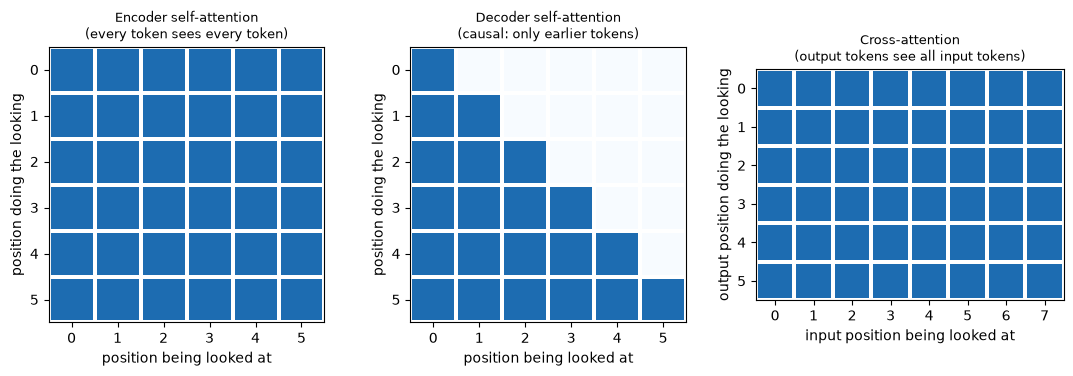

In [8]:
def mask_grid(kind, T=6, S=8):
    if kind == "encoder": return torch.ones(T, T)
    if kind == "decoder": return torch.tril(torch.ones(T, T))
    return torch.ones(T, S)                          # cross-attention: target positions x source positions
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, (kind, title) in zip(axes, [("encoder", "Encoder self-attention\n(every token sees every token)"),
                                    ("decoder", "Decoder self-attention\n(causal: only earlier tokens)"),
                                    ("cross", "Cross-attention\n(output tokens see all input tokens)")]):
    g = mask_grid(kind)
    ax.pcolormesh(g, cmap="Blues", vmin=0, vmax=1.3, edgecolors="white", linewidth=1.5)
    ax.invert_yaxis(); ax.set_aspect("equal")
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("input position being looked at" if kind == "cross" else "position being looked at")
    ax.set_ylabel("output position doing the looking" if kind == "cross" else "position doing the looking")
    ax.set_xticks(np.arange(g.shape[1]) + 0.5, range(g.shape[1])); ax.set_yticks(np.arange(g.shape[0]) + 0.5, range(g.shape[0]))
plt.tight_layout(); plt.show()

The three grids show the three patterns. Each row is a position doing the looking; each column is a position being looked at; blue means "allowed".

**Encoder-only (bidirectional).** Every token may look at every other token, before and after it (left grid). This gives the richest possible understanding of a complete input, so encoders are used to *understand* text: classify it, extract information from it, or produce embeddings for search. The best-known example is BERT. Encoders cannot generate text, because during generation the future tokens do not exist yet.

**Decoder-only (causal).** Each token may look only at itself and the tokens **before** it (middle grid). This is called a **causal mask**, because the output at each position can only depend on what came earlier, just as a writer can only build on what has already been written. This is exactly what you need to **generate** text one token at a time. GPT-style language models, including the chat assistants you may have used, are decoder-only. So is the model we build in this module.

**Encoder–decoder.** An encoder reads the whole input bidirectionally; a decoder generates the output causally, and at every layer it also looks at the encoder's output through **cross-attention** (right grid: every output position may look at every input position). This suits tasks that turn one sequence into another, such as translation or summarisation. The original Transformer was of this kind; T5 is a well-known modern example.

We can verify the difference between bidirectional and causal attention directly. Below, two inputs differ only in their **last** character: "the king is dead" and "the king is deaf". We run both through our model with and without the causal mask, and check whether the output at the **first** position changes.

In [9]:
a = torch.tensor([encode("the king is dead")])
b = torch.tensor([encode("the king is deaf")])            # only the LAST character differs
with torch.no_grad():
    for causal, name in [(False, "encoder-style (bidirectional)"), (True, "decoder-style (causal)")]:
        diff = (model(a, causal=causal)[0, 0] - model(b, causal=causal)[0, 0]).abs().max().item()
        print(f"{name:<31} change in the output at position 0: {diff:.6f}")

encoder-style (bidirectional)   change in the output at position 0: 0.095371
decoder-style (causal)          change in the output at position 0: 0.000000


With bidirectional attention, changing the last character changes the output at position 0 (by up to 0.095371): the first token can "see" the end of the sentence. With the causal mask, the change is exactly 0.000000: the first token cannot see anything after it. The mask does exactly what it promises.

For completeness, here is PyTorch's full encoder–decoder `nn.Transformer`, with a source sequence of 10 tokens (say, an English sentence) and the first 7 tokens of a target sequence (its translation, generated so far):

In [10]:
torch.manual_seed(0)
seq2seq = nn.Transformer(d_model=64, nhead=4, num_encoder_layers=2, num_decoder_layers=2,
                         dim_feedforward=256, batch_first=True)
src = torch.randn(1, 10, 64)       # e.g. an English sentence of 10 tokens, already embedded
tgt = torch.randn(1, 7, 64)        # the first 7 tokens of its French translation
out = seq2seq(src, tgt, tgt_mask=nn.Transformer.generate_square_subsequent_mask(7))
print("source:", tuple(src.shape), "| target so far:", tuple(tgt.shape), "| decoder output:", tuple(out.shape))

source: (1, 10, 64) | target so far: (1, 7, 64) | decoder output: (1, 7, 64)


The decoder produces one vector per **target** position, `(1, 7, 64)`, each informed by all 10 source tokens through cross-attention. To generate the 8th target token, a head would turn the last of these vectors into scores over the target vocabulary.

> **Key terms**
> - **Mask:** a grid that allows or blocks attention between each pair of positions.
> - **Bidirectional attention:** every token can attend to every other token (encoders).
> - **Causal attention:** each token can attend only to itself and earlier tokens (decoders).
> - **Cross-attention:** attention from the decoder's tokens to the encoder's output.
> - **Encoder-only / decoder-only / encoder–decoder:** the three Transformer families, used respectively for understanding, generating, and transforming one sequence into another.

> **Check yourself 3.** Which family would you choose for each task: (a) deciding whether an email is spam; (b) a chatbot; (c) translating German into English?

## 6. How Information Flows Through a Transformer

There is a powerful way to picture what happens inside the stack of blocks. Think of each token's vector as a **stream** that flows upward through the model. This is often called the **residual stream**. Each block does not replace the stream; it **adds** something to it: first whatever attention gathered from other tokens, then whatever the feed-forward network computed. (This "adding" is the residual connection, which you will meet properly in Note 6.4.)

So a token's vector starts as "this is the character `d` at position 8", and after each block it carries a little more about its surroundings. Let's watch this happen. We take two inputs with the same ending, "good lord" and "evil lord". Their final character, `d`, has the same ID and sits at the same position in both, so before any block their vectors must be identical. Do they stay identical?

In [11]:
s1 = torch.tensor([encode("good lord")])
s2 = torch.tensor([encode("evil lord")])
pos = 8                                                   # the final 'd' sits at position 8 in both
print(repr(decode(s1[0].tolist())[pos]), repr(decode(s2[0].tolist())[pos]))
with torch.no_grad():
    h1 = model.tok_emb(s1) + model.pos_emb(torch.arange(s1.shape[1]))
    h2 = model.tok_emb(s2) + model.pos_emb(torch.arange(s2.shape[1]))
    mask = nn.Transformer.generate_square_subsequent_mask(s1.shape[1])
    print(f"before any block: cosine of the two 'd' vectors = {F.cosine_similarity(h1[0, pos], h2[0, pos], dim=0):.3f}")
    for i, block in enumerate(model.blocks.layers):
        h1 = block(h1, src_mask=mask, is_causal=True); h2 = block(h2, src_mask=mask, is_causal=True)
        print(f"after block {i + 1}:     cosine of the two 'd' vectors = {F.cosine_similarity(h1[0, pos], h2[0, pos], dim=0):.3f}")

'd' 'd'
before any block: cosine of the two 'd' vectors = 1.000
after block 1:     cosine of the two 'd' vectors = 0.997
after block 2:     cosine of the two 'd' vectors = 0.989
after block 3:     cosine of the two 'd' vectors = 0.978


Before any block, the cosine similarity of the two `d` vectors is 1.000: identical, as expected. After block 1 it is 0.997, after block 2 0.989, and after block 3 0.978. Because each block mixes in information from earlier tokens, the `d` in "good lord" and the `d` in "evil lord" gradually become different vectors. This is a **contextual representation**, the thing that static embeddings could not provide in Note 5.3.

The effect is small here because the model is untrained: its attention is essentially random, so it mixes in context weakly and without purpose. After training, the context will matter far more.

> 🖼 *IMAGE 6.1.2 — The Residual Stream.* A diagram on a white background showing two vertical lanes side by side, labelled at the bottom "good lord" and "evil lord", each starting from a tile with the character "d". Each lane is a thick vertical arrow (the stream) rising through three horizontal dashed lines labelled "block 1", "block 2", "block 3". At each block, a small side-box with a "+" feeds into the stream: the left lane's boxes are tinted green and labelled "context from 'good'", the right lane's tinted red and labelled "context from 'evil'". The two lanes start the same colour (grey) at the bottom and gradually take on green and red tints as they rise. At the top, a small badge between the lanes reads "same token, different meaning". Takeaway: each block adds context to a token's vector, so identical tokens in different contexts drift apart.

> **Check yourself 4.** Why must the two `d` vectors be identical before the first block?

## 7. The Original Transformer vs. Modern Transformer Architectures *(Extension)*

*This section is optional background. The core ideas are unchanged; the details below are refinements you will meet in research papers and model documentation.*

The Transformer in *"Attention Is All You Need"* has been refined in several ways since it was published, mostly to make large models train more reliably:

- **Where normalisation goes.** The original placed layer normalisation *after* each attention and feed-forward step ("post-norm"). Most modern models place it *before* each step ("pre-norm"), which trains more stably in deep stacks. You will measure this difference yourself in Note 6.4.
- **Activation function.** The original feed-forward network used ReLU; modern models usually use smoother functions such as GELU or gated variants.
- **Positional information.** The original added fixed sine-and-cosine patterns. Many models instead learn position vectors, as ours does, and many large models use methods such as **rotary position embeddings (RoPE)** that encode relative positions inside attention itself.
- **Families.** The original was an encoder–decoder for translation. The most prominent models today are decoder-only.

These are refinements, not a different architecture. PyTorch builds both styles from the same layer class, with exactly the same number of parameters:

In [12]:
original = nn.TransformerEncoderLayer(64, 4, 256, dropout=0.0, activation="relu", batch_first=True, norm_first=False)
modern = nn.TransformerEncoderLayer(64, 4, 256, dropout=0.0, activation="gelu", batch_first=True, norm_first=True)
count = lambda m: sum(p.numel() for p in m.parameters())
print("original-style layer (post-norm, ReLU):", count(original), "parameters")
print("modern-style layer   (pre-norm, GELU): ", count(modern), "parameters")

original-style layer (post-norm, ReLU): 49984 parameters
modern-style layer   (pre-norm, GELU):  49984 parameters


Both layers have 49,984 parameters. The only differences are the order of operations (`norm_first`) and the activation function: the same components, arranged slightly differently.

## 8. Beyond Text: Vision Transformers and Multimodal Models *(Extension)*

Nothing in a Transformer block is specific to text. A block only needs a sequence of vectors. So if you can turn something into a sequence of vectors, you can process it with a Transformer.

The **Vision Transformer (ViT)** does exactly this for images. It cuts an image into a grid of small square **patches**, flattens each patch into a list of pixel values, and passes each through a linear layer to make a vector. Those patch vectors are then treated just like word embeddings. Here is the idea applied to a 28×28 Fashion-MNIST image, cut into 7×7 patches:

image: (28, 28) | patches: (4, 4, 7, 7) | patch tokens: (16, 49)
patch embeddings: (1, 16, 64) -> after a Transformer block: (1, 16, 64)


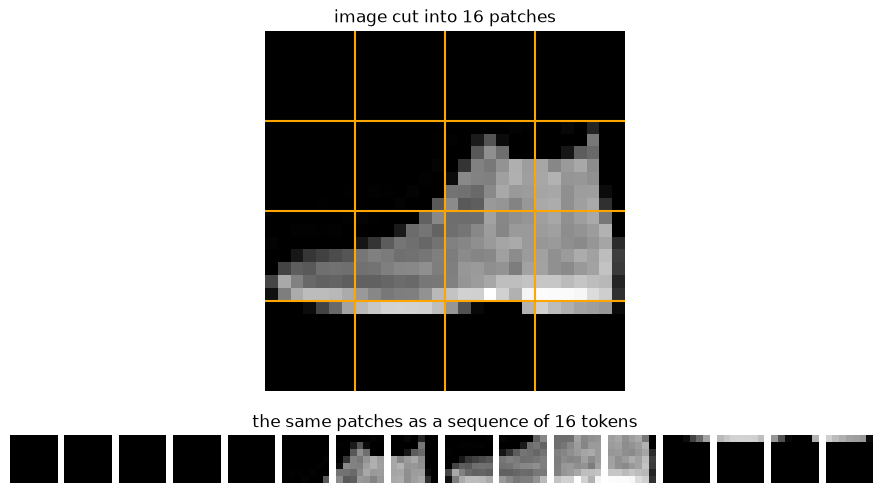

In [13]:
URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/t10k-images-idx3-ubyte.gz"
os.makedirs("data/fashion", exist_ok=True)
FP = "data/fashion/t10k-images-idx3-ubyte.gz"
if not os.path.exists(FP):
    urllib.request.urlretrieve(URL, FP)
with gzip.open(FP) as fh:
    img = torch.tensor(np.frombuffer(fh.read(), np.uint8, offset=16)[:784].reshape(28, 28), dtype=torch.float32) / 255
P = 7
patches = img.unfold(0, P, P).unfold(1, P, P)             # (4, 4, 7, 7): a 4x4 grid of 7x7 patches
tokens = patches.reshape(-1, P * P)                       # (16, 49): 16 "tokens", 49 numbers each
print("image:", tuple(img.shape), "| patches:", tuple(patches.shape), "| patch tokens:", tuple(tokens.shape))
patch_embed = nn.Linear(P * P, D_MODEL)
with torch.no_grad():
    seq = patch_embed(tokens).unsqueeze(0)                # (1, 16, 64): now looks exactly like a text sequence
    out = model.blocks.layers[0](seq)                     # the same kind of block, no mask
print("patch embeddings:", tuple(seq.shape), "-> after a Transformer block:", tuple(out.shape))
fig, axes = plt.subplots(2, 1, figsize=(9, 5.4), gridspec_kw={"height_ratios": [3, 1]})
axes[0].imshow(img, cmap="gray")
for k in range(1, 4):
    axes[0].axhline(k * P - 0.5, color="orange"); axes[0].axvline(k * P - 0.5, color="orange")
axes[0].set_title("image cut into 16 patches"); axes[0].axis("off")
strip = torch.cat([torch.cat([patches[r, c], torch.ones(P, 1)], 1) for r in range(4) for c in range(4)], 1)
axes[1].imshow(strip, cmap="gray"); axes[1].set_title("the same patches as a sequence of 16 tokens"); axes[1].axis("off")
plt.tight_layout(); plt.show()

The 28×28 image becomes a 4×4 grid of patches, `(4, 4, 7, 7)`, which we flatten into a sequence of 16 "tokens" of 49 numbers each, `(16, 49)`. A linear layer turns each into a 64-number vector, giving `(1, 16, 64)`: exactly the shape of a 16-token text sequence. We can then pass it through the same kind of Transformer block we used for Shakespeare, and get back `(1, 16, 64)`. (In a real ViT, a position embedding is added too, so the model knows where each patch came from.)

Notice how this connects back to Module 5. A CNN builds in the assumption that nearby pixels belong together. A ViT does not: from its first layer, any patch can attend to any other patch. With enough training data, this flexibility pays off, which is why many modern vision models are Transformers.

The same trick powers **multimodal** models. Turn image patches, audio frames or video frames into vectors, put them in the same sequence as text tokens, and one Transformer can attend across all of them. That is how assistants that "see" an uploaded image work: the image becomes a set of vectors placed alongside the words of your question.

> **Check yourself 5.** A 224×224 image is cut into 16×16 patches. How many patch tokens does the Vision Transformer receive?

## Putting It All Together

A Transformer is a pipeline. Text is split into **tokens** and converted to IDs. **Token embeddings** and **position embeddings** turn each ID into a vector of size `d_model`. A stack of **Transformer blocks** then refines every token's vector: in each block, **attention** moves information between tokens and a **feed-forward network** processes each token on its own, and both *add* their results to the token's **residual stream**. Finally, an **output head** turns each vector into one score per vocabulary entry.

In our small model, a 32-character input flowed through as `(1, 32)` → `(1, 32, 64)` → three blocks that kept that shape → `(1, 32, 65)` logits: 32 next-character predictions from a single forward pass. Of its 162,561 parameters, 61.1% sit in the feed-forward networks and 30.7% in attention.

What separates the Transformer families is the **mask**. Encoders let every token see every token, which is ideal for understanding. Decoders use a **causal mask**, so each token sees only the past, which is needed for generation; we confirmed that a change at the end of the input left the first position's output exactly unchanged. Encoder–decoders combine the two with **cross-attention**. And because blocks only need a sequence of vectors, the same design works for image patches and mixed modalities.

> 🖼 *IMAGE 6.1.3 — Module 6 Roadmap.* A horizontal roadmap on a white background built on the Transformer stack from IMAGE 6.1.1, drawn small on the left. Five numbered signposts point to parts of it: "6.2 Inputs: tokens, IDs, embeddings, positions" pointing at the bottom; "6.3 Attention: queries, keys, values, masks, heads" pointing at the blue attention box; "6.4 The block: feed-forward, residuals, layer norm" pointing at the whole block card; "6.5 The full model: decoder-only, output head" pointing at the top; "6.6 Training and generation" pointing at a small text page emerging from the top. Takeaway: each remaining note of Module 6 opens up one part of the system you have just seen working.

## Summary

- A Transformer turns a sequence of tokens into a sequence of enriched vectors and then into predictions: tokens → embeddings (+ positions) → stacked blocks → output head.
- It was designed to remove the problems of recurrent networks: long chains, a fixed-size memory and sequential computation. It processes every position in parallel.
- Each block keeps the shape `(batch, tokens, d_model)`, so blocks can be stacked freely.
- **Attention** moves information between tokens; the **feed-forward network** processes each token separately. In our model, the feed-forward networks hold 61.1% of the parameters.
- **Encoder-only** models see in both directions (understanding), **decoder-only** models use a causal mask (generation), and **encoder–decoder** models connect the two with cross-attention (sequence-to-sequence tasks).
- Each block adds to a token's **residual stream**, gradually turning identical tokens in different contexts into different, contextual vectors.
- Modern Transformers refine the original with pre-norm, GELU and new position methods. Vision Transformers apply the same blocks to sequences of image patches.

## Glossary

| Term | Meaning |
|---|---|
| Transformer | A network of stacked attention and feed-forward blocks that processes all tokens in parallel. |
| Token / token ID | A unit of text, and its number in the vocabulary. |
| Token embedding | A learned vector for each token ID. |
| Position embedding | A vector added to each token's embedding to encode its position. |
| `d_model` | The length of each token's vector inside the model. |
| Transformer block | One layer of attention plus a feed-forward network, with the same input and output shape. |
| Attention | The mechanism by which tokens gather information from other tokens, weighted by relevance. |
| Feed-forward network (FFN) | A small MLP applied separately to each token's vector. |
| Output head | The final linear layer that turns vectors into vocabulary scores. |
| Logits | Raw output scores, before softmax. |
| Entropy | A measure of how spread out a probability distribution is. |
| Mask | A grid that allows or blocks attention between pairs of positions. |
| Causal mask | A mask that lets each position see only itself and earlier positions. |
| Encoder / decoder | A stack using bidirectional / causal self-attention. |
| Cross-attention | Attention from decoder tokens to encoder outputs. |
| Residual stream | A token's vector viewed as a stream that each block adds to. |
| Pre-norm / post-norm | Layer normalisation placed before / after each sub-layer. |
| Vision Transformer (ViT) | A Transformer that treats image patches as tokens. |
| Multimodal | Involving more than one type of data, such as images and text. |

## Answers to Check Yourself

**1.** `(8, 50, 65)`: 8 sequences, 50 positions each, and 65 scores (one per character) at every position.

**2.** Attention moves information *between* tokens, letting each token gather what is relevant from the others. The feed-forward network processes the information *within* each token's vector, separately for every token.

**3.** (a) Encoder-only: you need to understand a complete email, not generate text. (b) Decoder-only: a chatbot generates its reply one token at a time. (c) Encoder–decoder: an encoder reads the whole German sentence and a decoder generates the English one, using cross-attention to consult the German. (Large decoder-only models can also translate, by treating the German text and its translation as one long sequence.)

**4.** Before the first block, a token's vector is just its token embedding plus its position embedding. Both `d` tokens have the same ID and the same position (8), so they get exactly the same two vectors and the same sum. No information from other tokens has been mixed in yet.

**5.** 224 / 16 = 14 patches along each side, so 14 × 14 = 196 patch tokens.